In [121]:
import numpy as np 
import matplotlib.pyplot as plt

In [122]:
# Define profiles 


PROFILES = {
    "random_walk" : {
        "omega_max" : np.pi / 2, 
        "omega_min" : 0
    }, 
    "desynchronized_sine" : {
        "omega_1" : 5 * np.sqrt(2), 
        "omega_2" : 2, 
        "phi" : 15
    }, 
    "constant_speed_ratio" : {
        "omega_max" : np.pi / 2, 
        "omega_min" : 0, 
        "factor" : 0.732
    }, 
    "static_1g" : {
        "omega_1" : 0, 
        "omega_2" : 0
    }, 
    "clinostat_1d" : {
        "omega_1" : 0, 
        "omega_2" : np.pi / 4
    }, 
    "centrifuge_sweep": {
        "omega_max": np.pi, # Maximum speed ceiling [rad/s] (~30 RPM)
        "tau": 25.0,        # Characteristic saturation time [s] (~63% of omega_max at t = tau)
    },
}


In [ ]:
def generate_random_walk(duration_s: float, dt: float):
    """
    Generate random walk trajectory using Gaussian speed sampling.
    Angular positions are integrated using cumulative discrete steps.
    """
    N = int(duration_s / dt)
    timestamp = np.linspace(0.0, duration_s, N)
    
    cfg = PROFILES["random_walk"]
    omega_max = cfg["omega_max"]
    omega_min = cfg["omega_min"]
    mean_speed = (omega_max - omega_min) / 2.0
    scale_speed = (omega_max - omega_min) / 4.0

    # Draw random speeds
    omega1 = np.random.normal(loc=mean_speed, scale=scale_speed, size=N)
    omega2 = np.random.normal(loc=mean_speed, scale=scale_speed, size=N)

    # Correct discrete time integration: theta = sum(omega * dt)
    theta1 = np.cumsum(omega1) * dt
    theta2 = np.cumsum(omega2) * dt

    return timestamp, theta1, theta2, omega1, omega2


def generate_desynchronized_sine(durations_s: float, step_s: float):
    """
    Generate harmonic desynchronized trajectory covering the spherical space.
    Positions and velocities are evaluated analytically.
    """
    cfg = PROFILES["desynchronized_sine"]
    w1 = cfg.get("omega_1", cfg.get("omega1", 1.0))
    w2 = cfg.get("omega_2", cfg.get("omega2", np.sqrt(2)))
    phi = cfg.get("phi", 0.0)
    a1 = cfg.get("amp1", np.pi)
    a2 = cfg.get("amp2", np.pi)

    N = int(durations_s / step_s)
    timestamp = np.linspace(0.0, durations_s, N)

    # Analytical harmonic positions
    theta1 = a1 * np.sin(w1 * timestamp)
    theta2 = a2 * np.sin(w2 * timestamp + phi)

    # Exact analytical time derivatives
    omega1 = a1 * w1 * np.cos(w1 * timestamp)
    omega2 = a2 * w2 * np.cos(w2 * timestamp + phi)

    return timestamp, theta1, theta2, omega1, omega2


def generate_constant_speed_ratio(durations_s: float, step_s: float, omega: float = None):
    """
    Generate continuous rotation with fixed desynchronized gear ratio.
    omega1 = omega, omega2 = omega * factor.
    """
    cfg = PROFILES["constant_speed_ratio"]
    if omega is None:
        omega_min = cfg["omega_min"]
        omega_max = cfg["omega_max"]
        omega = (omega_max + omega_min) / 2.0

    factor = cfg["factor"]
    N = int(durations_s / step_s)
    timestamp = np.linspace(0.0, durations_s, N)

    w1_val = float(omega)
    w2_val = float(omega * factor)

    omega1 = np.full(N, w1_val)
    omega2 = np.full(N, w2_val)

    # Analytical integration for constant speed: theta(t) = omega * t
    theta1 = w1_val * timestamp
    theta2 = w2_val * timestamp

    return timestamp, theta1, theta2, omega1, omega2


def generate_static_1g(durations_s: float, step_s: float):
    """
    Generate static ground baseline control trajectory (fixed 1g reference).
    """
    N = int(durations_s / step_s)
    timestamp = np.linspace(0.0, durations_s, N)

    theta1 = np.zeros(N)
    theta2 = np.zeros(N)
    omega1 = np.zeros(N)
    omega2 = np.zeros(N)

    return timestamp, theta1, theta2, omega1, omega2


def generate_clinostat_1d(durations_s: float, step_s: float):
    """
    Generate single-axis constant 2D clinostat rotation (axis 1 fixed, axis 2 rotating).
    """
    w2_val = PROFILES["clinostat_1d"].get("omega_2", PROFILES["clinostat_1d"].get("omega_1", np.pi / 2))
    N = int(durations_s / step_s)
    timestamp = np.linspace(0.0, durations_s, N)

    omega1 = np.zeros(N)
    omega2 = np.full(N, w2_val)

    theta1 = np.zeros(N)
    theta2 = w2_val * timestamp

    return timestamp, theta1, theta2, omega1, omega2


def generate_centrifuge_sweep(durations_s: float, step_s: float):
    """Generate a bounded saturation sweep trajectory for centrifugal testing.

    The angular velocity approaches omega_max smoothly using an exponential
    saturation curve: omega(t) = omega_max * (1 - exp(-t / tau)).
    Angles theta1 and theta2 are integrated using the constant time step dt.
    """
    # Retrieve profile kinematic parameters
    cfg = PROFILES.get("centrifuge_sweep", {})
    omega_max = cfg.get("omega_max", np.pi)
    tau = cfg.get("tau", durations_s / 4.0)

    # Build temporal discretization
    N = int(durations_s / step_s)
    timestamp = np.linspace(0.0, durations_s, N)
    dt = float(timestamp[1] - timestamp[0]) if N > 1 else step_s

    # Compute bounded velocity profiles
    omega1 = omega_max * (1.0 - np.exp(-timestamp / tau))
    omega2 = omega_max * (1.0 - np.exp(-timestamp / tau))

    # Integrate angular velocities to obtain continuous angular positions
    # theta(t) = \int omega(tau) dtau via discrete cumulative trapezoid/rectangle
    theta1 = np.cumsum(omega1) * dt
    theta2 = np.cumsum(omega2) * dt

    return timestamp, theta1, theta2, omega1, omega2

In [124]:
# Trajectory.generate() wrapper 

def generate(durations_s: float, step_s: float, profile: str, omega: float = None): 
    """
    Generate a Trajectory object using a specific profile. 
    """

    # Called asked generator function
    match profile: 
        case "random_walk": 
            values = generate_random_walk(
                durations_s, 
                step_s
            )
        case "desynchronized_sine": 
            values = generate_desynchronized_sine(
                durations_s, 
                step_s
            )
        case "constant_speed_ratio": 
            values = generate_constant_speed_ratio(
                durations_s, 
                step_s, 
                omega
            )
        case "static_1g": 
            values = generate_static_1g(
                durations_s, 
                step_s
            )
        case "clinostat_1d": 
            values = generate_clinostat_1d(
                durations_s, 
                step_s
            )
        case "centrifuge_sweep": 
            values = generate_centrifuge_sweep(
                durations_s, 
                step_s
            ) 
        case _: 
            # Default one 
            raise ValueError(f"Invalid trajectory profile, use : {PROFILES.keys}")

    # Unpack values
    return values 



In [125]:


def plot_motor_trajectory_diagnostics(
    timestamp: np.ndarray,
    theta1: np.ndarray,
    theta2: np.ndarray,
    omega1: np.ndarray,
    omega2: np.ndarray,
    profile_name: str = "",
) -> plt.Figure:
    """Affiche un tableau de bord complet d'inspection cinématique et spectrale

    d'une trajectoire moteur RPM à deux axes.
    """
    dt = float(timestamp[1] - timestamp[0]) if len(timestamp) > 1 else 1.0
    n_samples = len(timestamp)

    # 1. Calcul des accélérations angulaires alpha_i = d(omega_i)/dt
    alpha1 = np.gradient(omega1, timestamp)
    alpha2 = np.gradient(omega2, timestamp)

    # 2. Décomposition spectrale (FFT) unilatérale sur les vitesses
    freqs = np.fft.rfftfreq(n_samples, d=dt)
    fft_w1 = (2.0 / n_samples) * np.abs(
        np.fft.rfft(omega1 - np.mean(omega1))
    )
    fft_w2 = (2.0 / n_samples) * np.abs(
        np.fft.rfft(omega2 - np.mean(omega2))
    )
    if len(fft_w1) > 0:
        fft_w1[0] /= 2.0
        fft_w2[0] /= 2.0

    # 3. Construction de la figure
    fig, axs = plt.subplots(4, 2, figsize=(14, 12), sharex=False)
    title = f"Diagnostic Cinématique & Spectral"
    if profile_name:
        title += f" — Profil: {profile_name}"
    fig.suptitle(title, fontsize=13, fontweight="bold", y=0.99)

    col_c1 = "#2B6CB0"  # Axe 1 (Cardan interne)
    col_c2 = "#DD6B20"  # Axe 2 (Cardan externe)

    # --- LIGNE 1 : Positions angulaires ---
    # 1.A : Angle déroulé (continu)
    ax = axs[0, 0]
    ax.plot(timestamp, theta1, label=r"$\theta_1$ (brut)", color=col_c1, lw=1.2)
    ax.plot(timestamp, theta2, label=r"$\theta_2$ (brut)", color=col_c2, lw=1.2)
    ax.set_ylabel("Angle cumulé [rad]", fontsize=9, fontweight="bold")
    ax.set_title("Positions angulaires cumulées", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)

    # 1.B : Angle modulo [-pi, pi] (orientation réelle sur le cercle)
    ax = axs[0, 1]
    th1_wrap = (theta1 + np.pi) % (2 * np.pi) - np.pi
    th2_wrap = (theta2 + np.pi) % (2 * np.pi) - np.pi
    ax.plot(timestamp, th1_wrap, label=r"$\theta_1 2\pi$", color=col_c1, lw=0.8, alpha=0.7)
    ax.plot(timestamp, th2_wrap, label=r"$\theta_2 2\pi$", color=col_c2, lw=0.8, alpha=0.7)
    ax.set_yticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi])
    ax.set_yticklabels([r"$-\pi$", r"$-\pi/2$", "$0$", r"$\pi/2$", r"$\pi$"])
    ax.set_ylabel("Angle replié [rad]", fontsize=9, fontweight="bold")
    ax.set_title(r"Positions angulaires sur le cercle $[-\pi, \pi]$", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=8)

    # --- LIGNE 2 : Vitesses angulaires ---
    # 2.A : Axe 1
    ax = axs[1, 0]
    ax.plot(timestamp, omega1, color=col_c1, lw=1.0, label=r"$\omega_1(t)$")
    ax.axhline(np.mean(omega1), color="black", ls=":", lw=1, label=f"Moyenne: {np.mean(omega1):.2f}")
    ax.set_ylabel(r"$\omega_1$ [rad/s]", fontsize=9, fontweight="bold")
    ax.set_title("Vitesse angulaire — Axe 1", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)

    # 2.B : Axe 2
    ax = axs[1, 1]
    ax.plot(timestamp, omega2, color=col_c2, lw=1.0, label=r"$\omega_2(t)$")
    ax.axhline(np.mean(omega2), color="black", ls=":", lw=1, label=f"Moyenne: {np.mean(omega2):.2f}")
    ax.set_ylabel(r"$\omega_2$ [rad/s]", fontsize=9, fontweight="bold")
    ax.set_title("Vitesse angulaire — Axe 2", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)

    # --- LIGNE 3 : Accélérations angulaires ---
    # 3.A : Axe 1
    ax = axs[2, 0]
    ax.plot(timestamp, alpha1, color=col_c1, lw=0.8, alpha=0.85)
    ax.set_ylabel(r"$\alpha_1$ [$\mathrm{rad/s^2}$]", fontsize=9, fontweight="bold")
    ax.set_title(f"Accélération — Axe 1 (Max: {np.max(np.abs(alpha1)):.2e} rad/s²)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

    # 3.B : Axe 2
    ax = axs[2, 1]
    ax.plot(timestamp, alpha2, color=col_c2, lw=0.8, alpha=0.85)
    ax.set_ylabel(r"$\alpha_2$ [$\mathrm{rad/s^2}$]", fontsize=9, fontweight="bold")
    ax.set_title(f"Accélération — Axe 2 (Max: {np.max(np.abs(alpha2)):.2e} rad/s²)", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)

    # --- LIGNE 4 : Analyse spectrale & Espace des phases ---
    # 4.A : FFT des vitesses
    ax = axs[3, 0]
    ax.plot(freqs, fft_w1, label=r"Spectre $\omega_1$", color=col_c1, lw=1.0)
    ax.plot(freqs, fft_w2, label=r"Spectre $\omega_2$", color=col_c2, lw=1.0, alpha=0.8)
    ax.set_xlabel("Fréquence [Hz]", fontsize=9, fontweight="bold")
    ax.set_ylabel("Amplitude FFT", fontsize=9, fontweight="bold")
    ax.set_title("Spectre d'amplitude des vitesses (Bruit vs Périodicités)", fontsize=10)
    ax.set_xlim([0, min(1.0 / (2 * dt), 5.0)])  # Zoom jusqu'à 5 Hz max
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)

    # 4.B : Espace des phases couplé (theta1_wrap vs theta2_wrap)
    ax = axs[3, 1]
    ax.plot(th1_wrap, th2_wrap, color="#4A5568", lw=0.5, alpha=0.6)
    ax.scatter(th1_wrap[0], th2_wrap[0], color="green", s=30, label="Début", zorder=3)
    ax.scatter(th1_wrap[-1], th2_wrap[-1], color="red", s=30, label="Fin", zorder=3)
    ax.set_xlim([-np.pi, np.pi])
    ax.set_ylim([-np.pi, np.pi])
    ax.set_xticks([-np.pi, 0, np.pi])
    ax.set_xticklabels([r"$-\pi$", "$0$", r"$\pi$"])
    ax.set_yticks([-np.pi, 0, np.pi])
    ax.set_yticklabels([r"$-\pi$", "$0$", r"$\pi$"])
    ax.set_xlabel(r"$\theta_1 2\pi$ [rad]", fontsize=9, fontweight="bold")
    ax.set_ylabel(r"$\theta_2 2\pi$ [rad]", fontsize=9, fontweight="bold")
    ax.set_title("Parcours sur le tore angulaire $(T^2)$", fontsize=10)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper right", fontsize=8)

    fig.tight_layout()

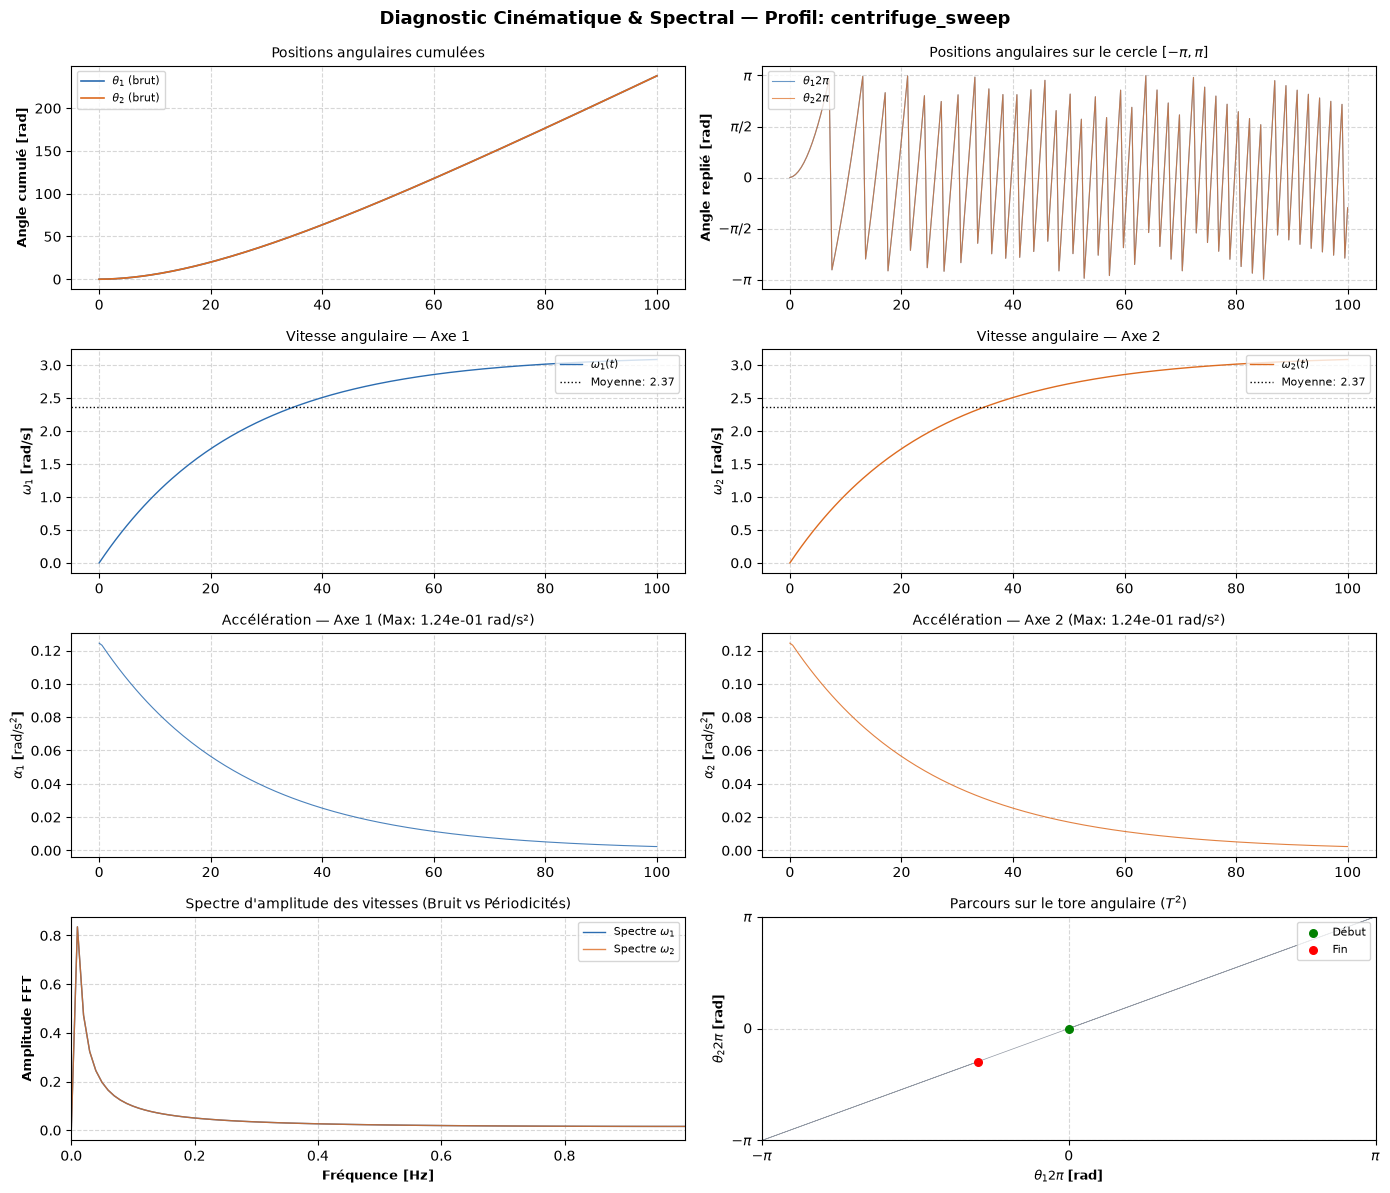

In [126]:

durations_s = 100.0
step_s = 0.5
# profile = "random_walk"
profile = "centrifuge_sweep"

timestamp, theta1, theta2, omega1, omega2 = generate(
    durations_s, 
    step_s, 
    profile
)

plot_motor_trajectory_diagnostics(
    timestamp, 
    theta1, 
    theta2, 
    omega1, 
    omega2, 
    profile
)

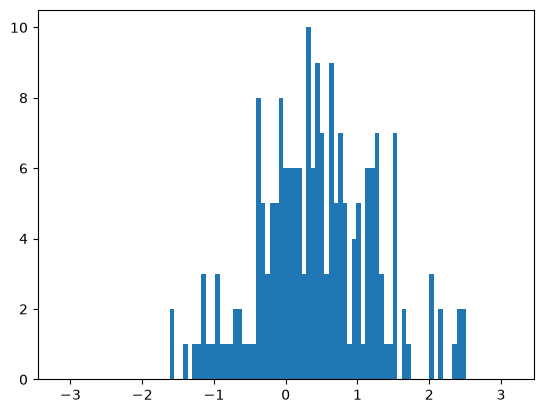

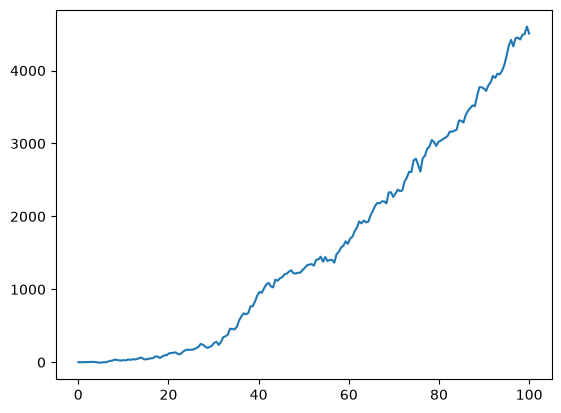

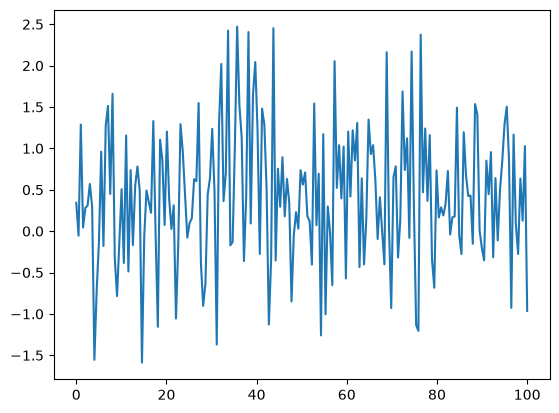

In [127]:
omega_max = np.pi / 4 
omega_min = 0
duration_s = 100
step_s = 0.5
N = int(duration_s / step_s)

timestamp = np.linspace(0, duration_s, N)
omega1 = np.random.normal(loc = (omega_max - omega_min) / 2, scale = omega_max - omega_min, size=(N,))
plt.hist(omega1, bins=np.linspace(-np.pi, np.pi, 100))
plt.show()

# Process positions 
theta1 = np.zeros(shape=(N,))
theta1[0] = 0
for i in range(1, len(theta1)): 
    theta1[i] = theta1[i-1] + timestamp[i] * omega1[i]

plt.plot(timestamp, theta1)
plt.show()

plt.plot(timestamp, omega1)
plt.show()